<a href="https://colab.research.google.com/github/iikauabrito/Codigos-Graduacao/blob/main/Com_validacao_cruzada.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
%matplotlib inline


In [ ]:
df = pd.read_excel(
    '/content/coleta_07_07_IA_aplicada_M5 (2).xlsx'
)

print(df.head())
print(df.columns)

# Entradas da rede neural
X = df[['Frequência', 'FT_1']].to_numpy(dtype=np.float32)

# Saída desejada
y = df[['Pressão PT2']].to_numpy(dtype=np.float32)

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()
X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

#df = pd.read_csv('/dados_demanda.csv', sep=';')
#df.drop(['TEMPO'], axis=1, inplace=True)

#data = np.array(df)
#data = tf.keras.utils.normalize(data, axis=1)

# Entradas e saídas da rede
#X = data[:, 0:5]
#y = data[:, 5:7]

# Separação dos dados em Treinamento, Teste e Validação
# Proporção adotada: 50% treino, 30% teste e 20% validação.
# Como os dados parecem estar em ordem temporal, foi usado shuffle=False
# para evitar misturar dados futuros com dados passados.

# Primeiro separa 50% para treinamento e deixa 50% temporário
x_train, x_temp, y_train, y_temp = train_test_split(
    X, y,
    train_size=0.50,
    shuffle=False
)

# Do conjunto temporário, separa 30% para teste e 20% para validação.
# Como x_temp representa 50% do total, então:
# teste = 30/50 = 0.60 do temporário
# validação = 20/50 = 0.40 do temporário
x_test, x_val, y_test, y_val = train_test_split(
    x_temp, y_temp,
    train_size=0.60,
    shuffle=False
)

print('Treinamento:', x_train.shape, y_train.shape)
print('Teste:      ', x_test.shape, y_test.shape)
print('Validação:  ', x_val.shape, y_val.shape)

print('Percentual treino:    ', round(len(x_train) / len(X) * 100, 2), '%')
print('Percentual teste:     ', round(len(x_test) / len(X) * 100, 2), '%')
print('Percentual validação: ', round(len(x_val) / len(X) * 100, 2), '%')

   Tempo (s)  Frequência  Pressão PT1  Pressão PT2      FT_1  valvula
0   0.037207       30.01     0.938308     4.172804  1.297565        0
1   1.061039       30.01     0.932512     4.150903  1.286157        0
2   2.092717       30.01     0.990472     4.157344  1.289959        0
3   3.127711       30.01     0.950544     4.174092  1.285465        0
4   4.148901       30.01     0.964712     4.118695  1.284774        0
Index(['Tempo (s)', 'Frequência', 'Pressão PT1', 'Pressão PT2', 'FT_1',
       'valvula'],
      dtype='object')
Treinamento: (612, 2) (612, 1)
Teste:       (367, 2) (367, 1)
Validação:   (246, 2) (246, 1)
Percentual treino:     49.96 %
Percentual teste:      29.96 %
Percentual validação:  20.08 %


In [ ]:
# Função para criar a rede neural
# Essa função será reutilizada no treinamento principal e na validação cruzada.
#def criar_modelo():
#    model = tf.keras.models.Sequential()
#    model.add(tf.keras.layers.Input(shape=(2,)))
#    model.add(tf.keras.layers.Dense(20, activation=tf.nn.sigmoid))
#    model.add(tf.keras.layers.Dense(20, activation=tf.nn.sigmoid))
#    model.add(tf.keras.layers.Dense(1, activation=tf.nn.sigmoid))

#    model.compile(
#        optimizer='adam',
#        loss='mean_squared_error',
#        metrics=['mean_squared_error']
#    )
#    return model

# Criando a rede
#model = criar_modelo()

# Treinando com conjunto de validação separado
#historico = model.fit(
#    x_train, y_train,
#    validation_data=(x_val, y_val),
#    epochs=5000
#)

# Função para criar a rede neural
def criar_modelo():
    model = tf.keras.models.Sequential()

    # Duas entradas: Frequência e FT_1
    model.add(tf.keras.layers.Input(shape=(2,)))

    # Camadas ocultas
    model.add(tf.keras.layers.Dense(20, activation='relu'))
    model.add(tf.keras.layers.Dense(20, activation='relu'))

    # Uma saída: Pressão PT2
    model.add(tf.keras.layers.Dense(1, activation='linear'))

    model.compile(
        optimizer='adam',
        loss='mean_squared_error',
        metrics=[
            tf.keras.metrics.MeanSquaredError(name='mse'),
            tf.keras.metrics.MeanAbsoluteError(name='mae')
        ]
    )

    return model


# Criando a rede
model = criar_modelo()

# Interrompe o treinamento quando a validação parar de melhorar
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=100,
    restore_best_weights=True
)

# Treinamento
historico = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=5000,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/5000
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0305 - mae: 0.1294 - mse: 0.0305 - val_loss: 0.3029 - val_mae: 0.5409 - val_mse: 0.3029
Epoch 2/5000
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0042 - mae: 0.0500 - mse: 0.0042 - val_loss: 0.1094 - val_mae: 0.3196 - val_mse: 0.1094
Epoch 3/5000
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0015 - mae: 0.0303 - mse: 0.0015 - val_loss: 0.0806 - val_mae: 0.2726 - val_mse: 0.0806
Epoch 4/5000
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.9228e-04 - mae: 0.0223 - mse: 9.9228e-04 - val_loss: 0.0605 - val_mae: 0.2332 - val_mse: 0.0605
Epoch 5/5000
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 7.4975e-04 - mae: 0.0182 - mse: 7.4975e-04 - val_loss: 0.0536 - val_mae: 0.2180 - val_mse: 0.0536
Epoch 6/5000
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 6.6485e-04 - mae: 0.0169 - mse: 6.6485e-04 - val_loss: 0.0486 - val_mae: 0.2082 - val_mse: 0.0486
Epoch 7/5000
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 5.9896e-04 - ma

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)
resultados_cv = []

for fold, (idx_treino, idx_validacao) in enumerate(tscv.split(X), start=1):
    x_treino_cv, x_validacao_cv = X[idx_treino], X[idx_validacao]
    y_treino_cv, y_validacao_cv = y[idx_treino], y[idx_validacao]

    modelo_cv = criar_modelo()
    modelo_cv.fit(
        x_treino_cv, y_treino_cv,
        epochs=5000,
        verbose=0
    )

    loss_cv, mse_cv, mae_cv = modelo_cv.evaluate(
        x_validacao_cv, y_validacao_cv,
        verbose=0
    )

    resultados_cv.append(mse_cv)
    print(f'Fold {fold} - MSE: {mse_cv:.6f}')

print()
print('MSE médio da validação cruzada:', np.mean(resultados_cv))
print('Desvio padrão do MSE:', np.std(resultados_cv))

Fold 1 - MSE: 0.004941
Fold 2 - MSE: 0.000447
Fold 3 - MSE: 0.000765
Fold 4 - MSE: 0.002514
Fold 5 - MSE: 0.002058

MSE médio da validação cruzada: 0.0021450807980727404
Desvio padrão do MSE: 0.0015969521750245144


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0070 - mae: 0.0775 - mse: 0.0070 
MSE na validação: 0.006970372051000595
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0018 - mae: 0.0302 - mse: 0.0018         
MSE no teste: 0.0018157101003453135
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


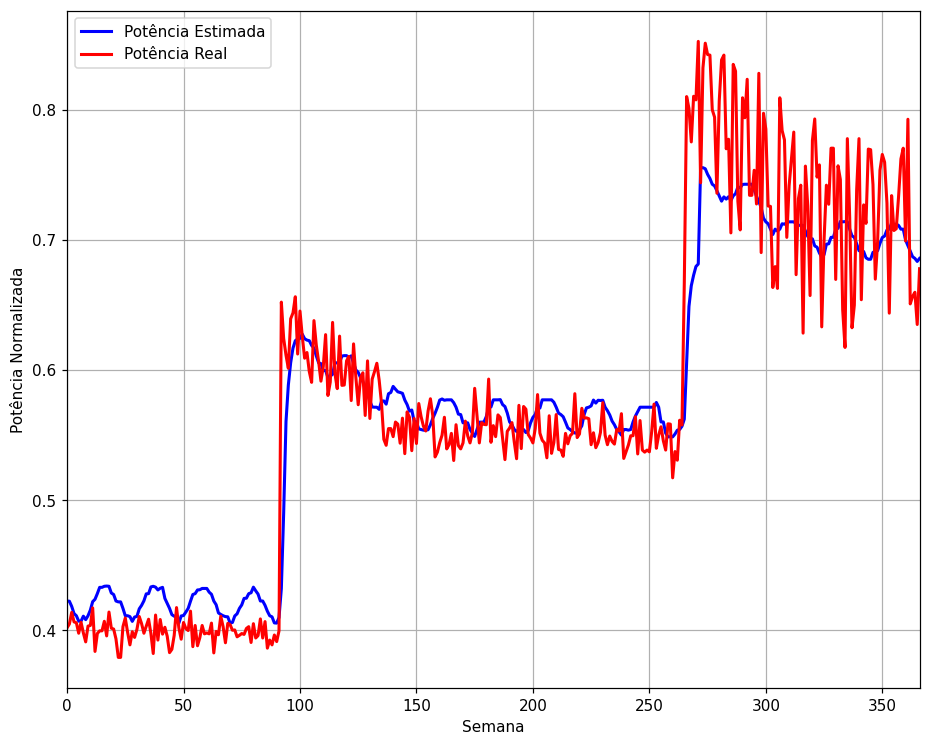

In [ ]:
# Avaliação no conjunto de validação
val_loss, val_mse, val_mae = model.evaluate(x_val, y_val)
print('MSE na validação:', val_mse)

# Avaliação final no conjunto de teste
# O conjunto de teste deve ser usado apenas ao final, após o treinamento e ajustes do modelo.
test_loss, test_mse, test_mae = model.evaluate(x_test, y_test)
print('MSE no teste:', test_mse)

y_pred = model.predict(x_test)

plt.figure(figsize=(10,8), dpi=110)
plt.plot(y_pred[:,0], lw=2, color='Blue')
plt.plot(y_test[:,0], lw=2, color='Red')
plt.grid(True)
plt.xlim([0, len(y_test)-1])
plt.xlabel('Semana')
plt.ylabel('Potência Normalizada')
plt.legend(['Potência Estimada','Potência Real'])

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


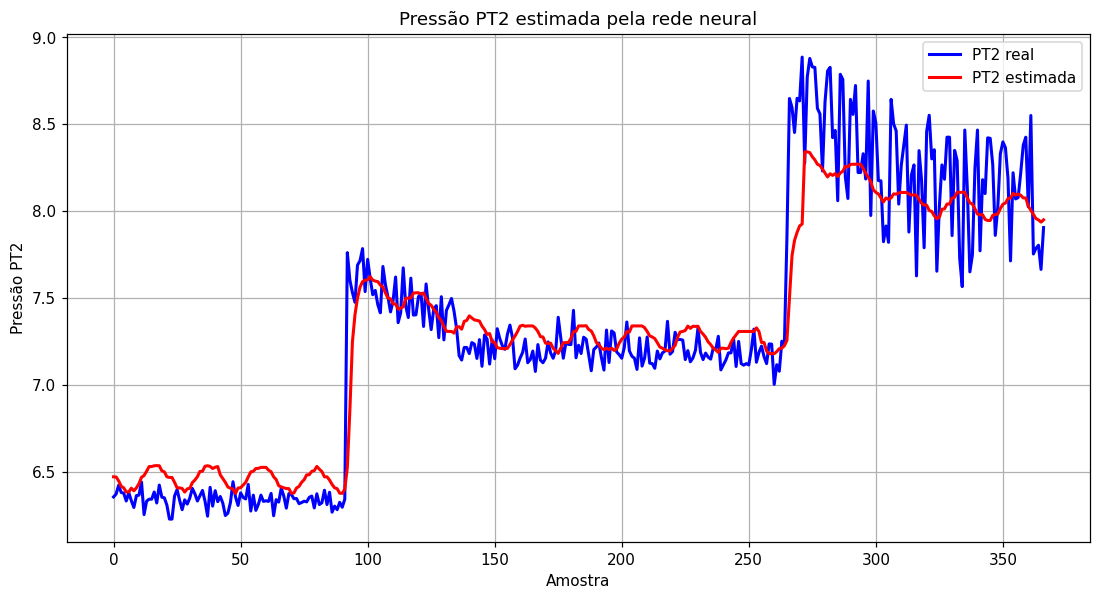

In [ ]:
y_pred_normalizado = model.predict(x_test)
y_pred = scaler_y.inverse_transform(y_pred_normalizado)
y_test_real = scaler_y.inverse_transform(y_test)

plt.figure(figsize=(12, 6), dpi=110)

plt.plot(y_test_real[:, 0], linewidth=2, color='Blue')
plt.plot(y_pred[:, 0], linewidth=2, color='Red')

plt.grid(True)
plt.xlabel('Amostra')
plt.ylabel('Pressão PT2')
plt.title('Pressão PT2 estimada pela rede neural')
plt.legend(['PT2 real', 'PT2 estimada'])

plt.show()

In [ ]:
import seaborn as sns

datas = pd.read_excel('/content/coleta_07_07_IA_aplicada_M5 (2).xlsx')
display(datas.head())

# Exemplo: Criando uma tabela pivô com colunas existentes
# Usando 'Frequência' como índice, 'valvula' como colunas e a média de 'Pressão PT2' como valores
pf = datas.pivot_table(values='Pressão PT2', index='Frequência', columns='valvula', aggfunc='mean')
display(pf.head())

,Tempo (s),Frequência,Pressão PT1,Pressão PT2,FT_1,valvula
0,0.037207,30.01,0.938308,4.172804,1.297565,0
1,1.061039,30.01,0.932512,4.150903,1.286157,0
2,2.092717,30.01,0.990472,4.157344,1.289959,0
3,3.127711,30.01,0.950544,4.174092,1.285465,0
4,4.148901,30.01,0.964712,4.118695,1.284774,0


valvula,0
Frequência,
30.01,4.212654
35.00,4.805359
35.28,5.796706
40.00,5.583264
45.00,6.389009


Text(70.72222222222221, 0.5, 'Número de neurônios na camada 1')

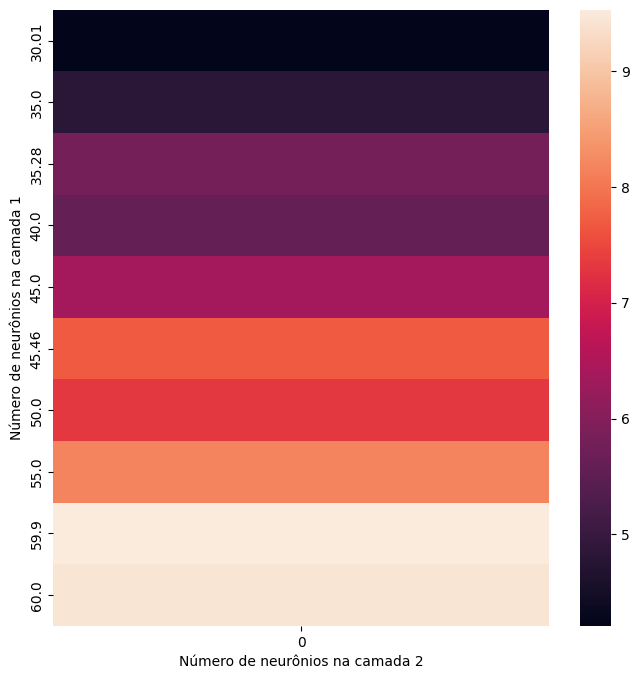

In [ ]:
#datas.head()
plt.figure(figsize=(8,8),dpi=100)
sns.heatmap(pf)
plt.xlabel('Número de neurônios na camada 2')
plt.ylabel('Número de neurônios na camada 1')

/tmp/ipykernel_610/1784186140.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_pred[:,0]-y_test[:,0])


<Axes: ylabel='Density'>

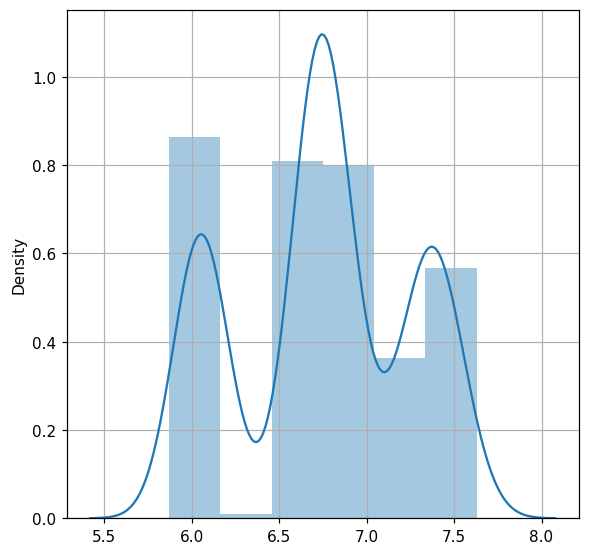

In [ ]:
plt.figure(figsize=(6,6),dpi=110)
plt.grid(True)
#plt.plot(y_pred[:,0]-y_test[:,0])
#plt.xlim([0,91])
sns.distplot(y_pred[:,0]-y_test[:,0])